# Experiment 20 — ResNet18 + DE + EWS

## 1. Architecture and Exponential Weight Smoothing

**Reference:** DEWS-EfficientNet (Zhang et al., 2026)

**Objective:** Determine whether Exponential Weight Smoothing
improves validation performance and training stability.

Architecture:
- ImageNet-pretrained ResNet18
- Directional Enhancement Block
- Exponential Weight Smoothing (decay = 0.995)

EWS maintains a moving average of the model's parameters:

    EMA = 0.995 × EMA + 0.005 × Current Weights

The online model is trained normally.
The EMA model is used for validation and checkpoint selection.

We initialize a fresh model rather than continuing from the
previously fine-tuned DE checkpoint.

This experiment uses the same 384×288 resolution and
driver-independent dataset split as Experiment 19.

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import copy
import random
import numpy as np

import torch
import torch.nn as nn

from pathlib import Path
from torchvision import models


# ============================================================
# 2. CONFIGURATION
# ============================================================

ROOT = Path("..")

SEED = 42
EWS_DECAY = 0.995

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("EWS decay:", EWS_DECAY)


# ============================================================
# 3. DIRECTIONAL ENHANCEMENT BLOCK
# Same architecture as Experiment 19
# ============================================================

class DirectionalEnhancementBlock(nn.Module):

    def __init__(self, channels):
        super().__init__()

        # Local feature extraction: 3x3
        self.local_branch = nn.Sequential(
            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1,
                groups=channels,
                bias=False
            ),
            nn.BatchNorm2d(channels),
            nn.SiLU()
        )

        # Directional feature extraction: 1x5 then 5x1
        self.directional_branch = nn.Sequential(
            nn.Conv2d(
                channels,
                channels,
                kernel_size=(1, 5),
                padding=(0, 2),
                groups=channels,
                bias=False
            ),
            nn.BatchNorm2d(channels),
            nn.SiLU(),

            nn.Conv2d(
                channels,
                channels,
                kernel_size=(5, 1),
                padding=(2, 0),
                groups=channels,
                bias=False
            ),
            nn.BatchNorm2d(channels),
            nn.SiLU()
        )

        # Fuse the two branches
        self.fusion = nn.Sequential(
            nn.Conv2d(
                channels * 2,
                channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(channels),
            nn.SiLU()
        )

        # Initially behaves like an identity mapping
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):

        local = self.local_branch(x)

        directional = self.directional_branch(x)

        combined = torch.cat(
            [local, directional],
            dim=1
        )

        enhanced = self.fusion(combined)

        return x + self.gamma * enhanced


# ============================================================
# 4. RESNET18 + DE ARCHITECTURE
# ============================================================

class ResNet18WithDE(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        self.backbone = backbone

        self.de_block = DirectionalEnhancementBlock(512)

    def forward(self, x):

        b = self.backbone

        x = b.conv1(x)
        x = b.bn1(x)
        x = b.relu(x)
        x = b.maxpool(x)

        x = b.layer1(x)
        x = b.layer2(x)
        x = b.layer3(x)
        x = b.layer4(x)

        # Directional Enhancement
        x = self.de_block(x)

        x = b.avgpool(x)

        x = torch.flatten(x, 1)

        x = b.fc(x)

        return x


# ============================================================
# 5. CREATE FRESH IMAGENET-PRETRAINED MODEL
# ============================================================

backbone = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Replace ImageNet's 1000-class classifier
backbone.fc = nn.Linear(
    backbone.fc.in_features,
    10
)

# Create our DE-enhanced model
model_de_ews = ResNet18WithDE(
    copy.deepcopy(backbone)
).to(device)

print("\nResNet18 + DE initialized.")


# ============================================================
# 6. IMPLEMENT EXPONENTIAL WEIGHT SMOOTHING
# ============================================================

class ExponentialWeightSmoothing:

    def __init__(self, model, decay=0.995):

        self.decay = decay

        # Create an independent copy of the model
        self.shadow = copy.deepcopy(model)

        # The EWS model does not receive gradients
        self.shadow.requires_grad_(False)

        self.shadow.eval()

        self.num_updates = 0

    @torch.no_grad()
    def update(self, model):

        # Smooth learnable parameters
        for ema_param, model_param in zip(
            self.shadow.parameters(),
            model.parameters()
        ):

            ema_param.mul_(self.decay)

            ema_param.add_(
                model_param.detach(),
                alpha=1.0 - self.decay
            )

        # Copy BatchNorm running statistics and other buffers.
        # Implementation choice: buffers are not exponentially averaged.
        for ema_buffer, model_buffer in zip(
            self.shadow.buffers(),
            model.buffers()
        ):

            ema_buffer.copy_(model_buffer)

        self.num_updates += 1


# ============================================================
# 7. INITIALIZE EWS
# ============================================================

ews = ExponentialWeightSmoothing(
    model_de_ews,
    decay=EWS_DECAY
)

print("\nEWS initialized successfully!")


# ============================================================
# 8. VERIFY MODEL STRUCTURES
# ============================================================

online_params = sum(
    p.numel() for p in model_de_ews.parameters()
)

ews_params = sum(
    p.numel() for p in ews.shadow.parameters()
)

print("\nMODEL VERIFICATION")
print("-" * 45)

print(f"Online model parameters: {online_params:,}")
print(f"EWS model parameters:    {ews_params:,}")

print("Initial gamma:", model_de_ews.de_block.gamma.item())

# EWS and online model should start identically
same_weights = all(
    torch.equal(p1, p2)
    for p1, p2 in zip(
        model_de_ews.parameters(),
        ews.shadow.parameters()
    )
)

print("Identical initial weights:", same_weights)

assert online_params == 11_719_755
assert online_params == ews_params
assert same_weights

assert all(
    not p.requires_grad
    for p in ews.shadow.parameters()
)

# Verify EWS's numerical update on a tiny separate model
toy = nn.Linear(1, 1, bias=False).to(device)

with torch.no_grad():
    toy.weight.fill_(1.0)

toy_ews = ExponentialWeightSmoothing(
    toy,
    decay=EWS_DECAY
)

with torch.no_grad():
    toy.weight.fill_(3.0)

toy_ews.update(toy)

expected = 0.995 * 1.0 + 0.005 * 3.0

actual = toy_ews.shadow.weight.item()

print(f"EWS update test: {actual:.4f}")

assert abs(actual - expected) < 1e-5

print("\nSUCCESS: EWS implementation verified!")

Device: cuda
EWS decay: 0.995

ResNet18 + DE initialized.

EWS initialized successfully!

MODEL VERIFICATION
---------------------------------------------
Online model parameters: 11,719,755
EWS model parameters:    11,719,755
Initial gamma: 0.0
Identical initial weights: True
EWS update test: 1.0100

SUCCESS: EWS implementation verified!


## 2. Prepare Data for ResNet18 + DE + EWS

Use the same driver-independent split and preprocessing
as Experiment 19.

- 15,732 training images from 18 drivers
- 3,603 validation images from 4 unseen drivers
- Resolution: 384×288
- No horizontal flipping
- Same geometric and color augmentation

The final test set remains untouched.

In [2]:
# ============================================================
# 1. IMPORTS
# ============================================================

import pandas as pd
from PIL import Image

from torchvision import transforms
from torch.utils.data import Dataset, DataLoader


# ============================================================
# 2. PATHS AND CONFIGURATION
# ============================================================

IMAGE_ROOT = ROOT / "data/raw/imgs/train"

TRAIN_CSV = ROOT / "data/splits/driver_based/train.csv"
VAL_CSV = ROOT / "data/splits/driver_based/val.csv"

IMG_HEIGHT = 288
IMG_WIDTH = 384
BATCH_SIZE = 32


# ============================================================
# 3. LOAD DATASET METADATA
# ============================================================

train_df = pd.read_csv(TRAIN_CSV).reset_index(drop=True)
val_df = pd.read_csv(VAL_CSV).reset_index(drop=True)

train_drivers = set(train_df["subject"])
val_drivers = set(val_df["subject"])

assert train_drivers.isdisjoint(val_drivers)

assert len(train_df) == 15732
assert len(val_df) == 3603

print("Training images:", len(train_df))
print("Training drivers:", len(train_drivers))

print("Validation images:", len(val_df))
print("Validation drivers:", len(val_drivers))
print("Driver overlap:", train_drivers & val_drivers)


# ============================================================
# 4. TRANSFORMS — SAME AS EXPERIMENT 19
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((IMG_HEIGHT, IMG_WIDTH)),

    transforms.RandomAffine(
        degrees=5,
        translate=(0.04, 0.04),
        scale=(0.97, 1.03)
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_HEIGHT, IMG_WIDTH)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 5. DATASET CLASS
# ============================================================

class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = (
            IMAGE_ROOT /
            row["classname"] /
            row["img"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        label = int(row["classname"][1:])

        return image, label


# ============================================================
# 6. CREATE DATASETS
# ============================================================

train_dataset = DriverDataset(
    train_df,
    train_transform
)

val_dataset = DriverDataset(
    val_df,
    val_transform
)


# ============================================================
# 7. CREATE DATALOADERS
# ============================================================

def create_train_loader(seed=42):

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        generator=generator
    )


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ============================================================
# 8. VERIFY DATA
# ============================================================

images, labels = next(iter(val_loader))

print("\nBatch shape:", tuple(images.shape))
print("Labels shape:", tuple(labels.shape))

assert images.shape == (32, 3, 288, 384)

print("\nSUCCESS: Data is ready for training!")

Training images: 15732
Training drivers: 18
Validation images: 3603
Validation drivers: 4
Driver overlap: set()

Batch shape: (32, 3, 288, 384)
Labels shape: (32,)

SUCCESS: Data is ready for training!


## 3. Train ResNet18 + DE with Exponential Weight Smoothing

Train from fresh ImageNet-pretrained weights.

Training configuration:
- Optimizer: AdamW
- Backbone LR: 0.0001
- New-layer LR: 0.001
- Weight decay: 0.0001
- Maximum epochs: 15
- Minimum epochs: 7
- Early stopping patience: 5
- Random seed: 42
- EWS decay: 0.995

After every epoch:
1. Evaluate ordinary model weights.
2. Evaluate EWS-smoothed weights.
3. Calculate Accuracy and Macro-F1.
4. Save the best checkpoints separately.

The final test set remains untouched.

In [3]:
# ============================================================
# 1. IMPORTS
# ============================================================

import random
import time
import json

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# 2. CONFIGURATION
# ============================================================

MAX_EPOCHS = 15
MIN_EPOCHS = 7
PATIENCE = 5

BACKBONE_LR = 1e-4
NEW_LAYER_LR = 1e-3
WEIGHT_DECAY = 1e-4

MODEL_DIR = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/de_ews"
)

RESULT_DIR = (
    ROOT / "results/deep_learning/driver_based/"
    "resnet18/de_ews"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

ONLINE_CHECKPOINT = MODEL_DIR / "best_online_model.pt"
EWS_CHECKPOINT = MODEL_DIR / "best_ews_model.pt"


# ============================================================
# 3. REPRODUCIBILITY
# ============================================================

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ============================================================
# 4. OPTIMIZER — SAME AS EXPERIMENT 19
# ============================================================

feature_params = [
    p for name, p in model_de_ews.backbone.named_parameters()
    if not name.startswith("fc.")
]

classifier_params = list(
    model_de_ews.backbone.fc.parameters()
)

de_params = list(
    model_de_ews.de_block.parameters()
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": feature_params,
            "lr": BACKBONE_LR
        },
        {
            "params": classifier_params,
            "lr": NEW_LAYER_LR
        },
        {
            "params": de_params,
            "lr": NEW_LAYER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()


# ============================================================
# 5. VALIDATION FUNCTION
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=list(range(10)),
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1


# ============================================================
# 6. TRAINING FUNCTION
# ============================================================

def train_with_ews():

    assert ews.num_updates == 0, (
        "This model has already received EWS updates. "
        "Rerun Step 1 before starting a new training run."
    )

    assert model_de_ews.de_block.gamma.item() == 0.0

    set_seed(SEED)

    train_loader = create_train_loader(SEED)

    best_ews_f1 = -1.0
    best_online_f1 = -1.0

    best_ews_epoch = 0
    best_online_epoch = 0

    best_ews_accuracy = 0.0
    best_online_accuracy = 0.0

    epochs_without_improvement = 0

    history = []

    training_start = time.perf_counter()

    print("\n" + "=" * 65)
    print("TRAINING: RESNET18 + DE + EWS")
    print("=" * 65)

    print("Device:", device)
    print("EWS decay:", EWS_DECAY)
    print("Training images:", len(train_dataset))
    print("Validation images:", len(val_dataset))

    # ========================================================
    # EPOCH LOOP
    # ========================================================

    for epoch in range(1, MAX_EPOCHS + 1):

        epoch_start = time.perf_counter()

        # ----------------------------------------------------
        # A. TRAIN ONLINE MODEL
        # ----------------------------------------------------

        model_de_ews.train()

        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            # Forward propagation
            outputs = model_de_ews(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update ordinary model weights
            optimizer.step()

            # NEW: Update exponentially smoothed weights
            ews.update(model_de_ews)

            running_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct_train += (
                predictions == labels
            ).sum().item()

            total_train += labels.size(0)

        train_loss = running_loss / total_train
        train_accuracy = correct_train / total_train

        # ----------------------------------------------------
        # B. VALIDATE ORDINARY MODEL
        # ----------------------------------------------------

        online_accuracy, online_f1 = evaluate_model(
            model_de_ews,
            val_loader
        )

        # ----------------------------------------------------
        # C. VALIDATE EWS MODEL
        # ----------------------------------------------------

        ews_accuracy, ews_f1 = evaluate_model(
            ews.shadow,
            val_loader
        )

        # ----------------------------------------------------
        # D. SAVE BEST ORDINARY MODEL
        # ----------------------------------------------------

        if online_f1 > best_online_f1:

            best_online_f1 = online_f1
            best_online_accuracy = online_accuracy
            best_online_epoch = epoch

            torch.save(
                model_de_ews.state_dict(),
                ONLINE_CHECKPOINT
            )

        # ----------------------------------------------------
        # E. SAVE BEST EWS MODEL
        # ----------------------------------------------------

        if ews_f1 > best_ews_f1:

            best_ews_f1 = ews_f1
            best_ews_accuracy = ews_accuracy
            best_ews_epoch = epoch

            epochs_without_improvement = 0

            torch.save(
                ews.shadow.state_dict(),
                EWS_CHECKPOINT
            )

        else:

            epochs_without_improvement += 1

        # ----------------------------------------------------
        # F. RECORD HISTORY
        # ----------------------------------------------------

        epoch_seconds = time.perf_counter() - epoch_start

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "online_accuracy": online_accuracy,
            "online_macro_f1": online_f1,
            "ews_accuracy": ews_accuracy,
            "ews_macro_f1": ews_f1,
            "ews_updates": ews.num_updates,
            "epoch_seconds": epoch_seconds
        })

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train: {train_accuracy:.2%} | "
            f"Online Acc: {online_accuracy:.2%} | "
            f"Online F1: {online_f1:.2%} | "
            f"EWS Acc: {ews_accuracy:.2%} | "
            f"EWS F1: {ews_f1:.2%} | "
            f"Time: {epoch_seconds:.1f}s",
            flush=True
        )

        # ----------------------------------------------------
        # G. EARLY STOPPING BASED ON EWS MACRO-F1
        # ----------------------------------------------------

        if (
            epoch >= MIN_EPOCHS
            and epochs_without_improvement >= PATIENCE
        ):

            print("\nEarly stopping triggered.")
            break

    # ========================================================
    # 7. SAVE TRAINING HISTORY
    # ========================================================

    total_time = time.perf_counter() - training_start

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        RESULT_DIR / "training_history.csv",
        index=False
    )

    # ========================================================
    # 8. SAVE TRAINING SUMMARY
    # ========================================================

    summary = {
        "model": "ResNet18 + DE + EWS",
        "seed": SEED,
        "resolution": [384, 288],
        "train_images": len(train_dataset),
        "val_images": len(val_dataset),
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "min_epochs": MIN_EPOCHS,
        "patience": PATIENCE,
        "epochs_completed": len(history),
        "backbone_lr": BACKBONE_LR,
        "new_layer_lr": NEW_LAYER_LR,
        "weight_decay": WEIGHT_DECAY,
        "ews_decay": EWS_DECAY,
        "ews_updates": ews.num_updates,
        "best_online_epoch": best_online_epoch,
        "best_online_accuracy": float(best_online_accuracy),
        "best_online_macro_f1": float(best_online_f1),
        "best_ews_epoch": best_ews_epoch,
        "best_ews_accuracy": float(best_ews_accuracy),
        "best_ews_macro_f1": float(best_ews_f1),
        "training_seconds": total_time
    }

    with open(
        RESULT_DIR / "training_summary.json",
        "w"
    ) as f:
        json.dump(summary, f, indent=4)

    # ========================================================
    # 9. FINAL COMPARISON
    # ========================================================

    print("\n" + "=" * 65)
    print("TRAINING COMPLETED — EWS ABLATION")
    print("=" * 65)

    print("\nBEST ORDINARY MODEL")
    print("Epoch:", best_online_epoch)
    print(f"Accuracy: {best_online_accuracy:.2%}")
    print(f"Macro-F1: {best_online_f1:.2%}")

    print("\nBEST EWS MODEL")
    print("Epoch:", best_ews_epoch)
    print(f"Accuracy: {best_ews_accuracy:.2%}")
    print(f"Macro-F1: {best_ews_f1:.2%}")

    difference = (
        best_ews_f1 - best_online_f1
    ) * 100

    print(
        f"\nEWS Macro-F1 difference: "
        f"{difference:+.2f} percentage points"
    )

    print(
        f"\nTotal training time: "
        f"{total_time / 60:.2f} minutes"
    )

    print("\nCheckpoints saved:")
    print(ONLINE_CHECKPOINT)
    print(EWS_CHECKPOINT)

    return history_df, summary


# ============================================================
# 10. START TRAINING NOW
# ============================================================

history_ews, summary_ews = train_with_ews()


TRAINING: RESNET18 + DE + EWS
Device: cuda
EWS decay: 0.995
Training images: 15732
Validation images: 3603
Epoch 01/15 | Train: 94.65% | Online Acc: 90.90% | Online F1: 90.28% | EWS Acc: 88.87% | EWS F1: 87.82% | Time: 81.1s
Epoch 02/15 | Train: 99.57% | Online Acc: 86.62% | Online F1: 85.32% | EWS Acc: 89.31% | EWS F1: 87.65% | Time: 79.5s
Epoch 03/15 | Train: 99.36% | Online Acc: 87.76% | Online F1: 85.34% | EWS Acc: 89.20% | EWS F1: 87.68% | Time: 79.7s
Epoch 04/15 | Train: 99.73% | Online Acc: 89.26% | Online F1: 88.45% | EWS Acc: 89.15% | EWS F1: 87.98% | Time: 78.1s
Epoch 05/15 | Train: 99.55% | Online Acc: 90.31% | Online F1: 88.39% | EWS Acc: 86.54% | EWS F1: 84.88% | Time: 78.6s
Epoch 06/15 | Train: 99.67% | Online Acc: 91.01% | Online F1: 90.13% | EWS Acc: 87.57% | EWS F1: 86.04% | Time: 78.9s
Epoch 07/15 | Train: 99.61% | Online Acc: 91.73% | Online F1: 90.74% | EWS Acc: 86.21% | EWS F1: 83.84% | Time: 78.9s
Epoch 08/15 | Train: 99.88% | Online Acc: 92.23% | Online F1: 91.5

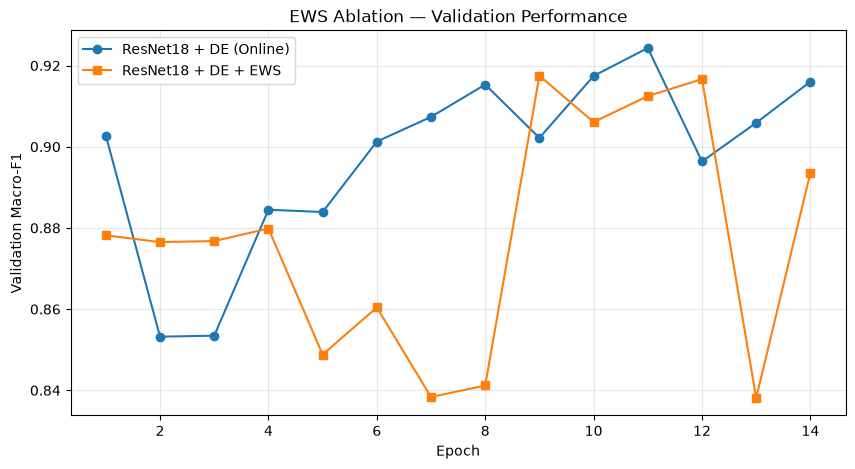

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_ews["epoch"],
    history_ews["online_macro_f1"],
    marker="o",
    label="ResNet18 + DE (Online)"
)

plt.plot(
    history_ews["epoch"],
    history_ews["ews_macro_f1"],
    marker="s",
    label="ResNet18 + DE + EWS"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("EWS Ablation — Validation Performance")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    RESULT_DIR / "ews_training_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()